In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from hurst import compute_Hc

# Set up matplotlib for inline plotting
%matplotlib inline


In [2]:
## Step 2: Fetch Market Data
## We will download S&P 500 data from Yahoo Finance for the years 2007 to 2009.


In [3]:
# Download S&P 500 data from Yahoo Finance for 2007-2009
ticker = "^GSPC"  # S&P 500 ticker
data = yf.download(ticker, start="2007-01-01", end="2009-12-31")
data['Returns'] = data['Adj Close'].pct_change().dropna()
data.head()


[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume,Returns
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,,
2007-01-03 00:00:00+00:00,1416.599976,1416.599976,1429.420044,1407.859985,1418.030029,3429160000,NaN
2007-01-04 00:00:00+00:00,1418.339966,1418.339966,1421.839966,1408.430054,1416.599976,3004460000,0.001228
2007-01-05 00:00:00+00:00,1409.709961,1409.709961,1418.339966,1405.750000,1418.339966,2919400000,-0.006085
2007-01-08 00:00:00+00:00,1412.839966,1412.839966,1414.979980,1403.969971,1409.260010,2763340000,0.002220
2007-01-09 00:00:00+00:00,1412.109985,1412.109985,1415.609985,1405.420044,1412.839966,3038380000,-0.000517


In [4]:
## Step 3: Define the Rolling Hurst Function
## We'll create a function to calculate the Hurst exponent over a moving window. If the series length is less than 100 (required by the `hurst` library), we’ll skip that window.


In [5]:
# Define a function to calculate Hurst Exponent over a moving window
def rolling_hurst(data, window_size=100):
    hurst_values = []
    for i in range(window_size, len(data)):
        series = data[i - window_size:i]
        # Check that the series length is >= 100 as required by compute_Hc
        if len(series) >= 100:
            H, c, data_rs = compute_Hc(series, kind='price', simplified=True)
            hurst_values.append(H)
        else:
            hurst_values.append(np.nan)  # Fill with NaN if window is too short
    return hurst_values


In [6]:
## Step 4: Calculate the Hurst Exponent
## Using the function we just defined, we’ll calculate the Hurst exponent with a rolling window of 100 days.


In [7]:
# Set window size for the rolling Hurst calculation
window_size = 100  # Adjusted window size to meet minimum length requirement

# Calculate Hurst exponent on a rolling basis
hurst_values = rolling_hurst(data['Adj Close'].dropna().values, window_size=window_size)

# Adjust the length of the Hurst values list to match the data for plotting
hurst_dates = data.index[window_size:]


In [8]:
## Step 5: Visualize the Data
## We’ll create two plots:
## 1. The S&P 500 adjusted closing prices.
## 2. The Hurst exponent over time, with reference lines for typical values:
## - \( H = 0.5 \): Indicates a random walk (no predictability).
## - \( H > 0.5 \): Suggests a trending behavior (predictable).
## - \( H < 0.5 \): Indicates mean-reverting behavior.


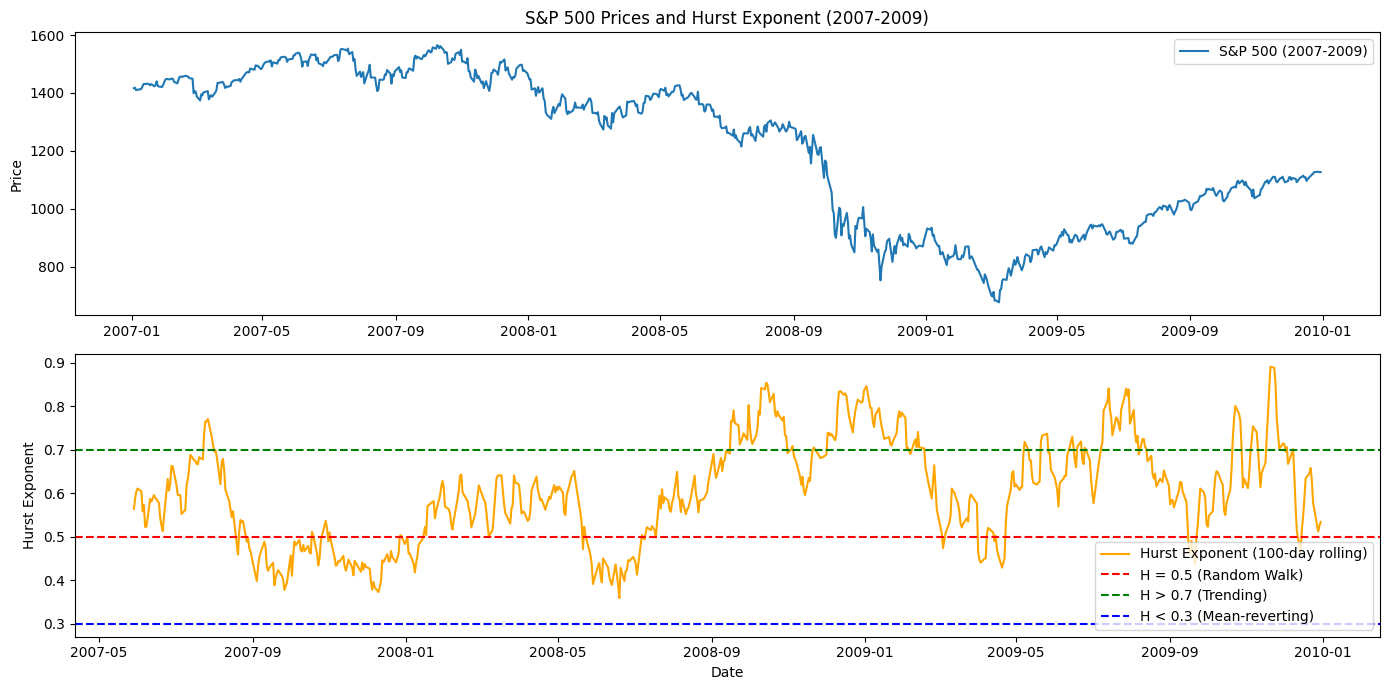

In [9]:
# Plot market data (S&P 500 adjusted close prices) and Hurst exponent
plt.figure(figsize=(14, 7))

# Plot S&P 500 prices
plt.subplot(2, 1, 1)
plt.plot(data.index, data['Adj Close'], label="S&P 500 (2007-2009)")
plt.title("S&P 500 Prices and Hurst Exponent (2007-2009)")
plt.ylabel("Price")
plt.legend()

# Plot Hurst exponent over time
plt.subplot(2, 1, 2)
plt.plot(hurst_dates, hurst_values, color='orange', label="Hurst Exponent (100-day rolling)")
plt.axhline(0.5, color='red', linestyle='--', label="H = 0.5 (Random Walk)")
plt.axhline(0.7, color='green', linestyle='--', label="H > 0.7 (Trending)")
plt.axhline(0.3, color='blue', linestyle='--', label="H < 0.3 (Mean-reverting)")
plt.xlabel("Date")
plt.ylabel("Hurst Exponent")
plt.legend()

plt.tight_layout()
plt.show()
